### Imports

In [1]:
import copy
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "paths.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate project root containing src/paths.py")
sys.path.insert(0, str(ROOT))

from src.paths import CONFIG, PROCESSED, SENSITIVITY
from src.bess_optimization import optimize_bess

# Ensure sensitivity output directory exists
SENSITIVITY.mkdir(parents=True, exist_ok=True)


### Load inputs

In [3]:
profile_options = [
    PROCESSED / "optimization_profile.csv",
    PROCESSED / "system_hourly_profile.csv",
]
profile_path = next((path for path in profile_options if path.is_file()), None)
candidates_path = PROCESSED / "candidate_bess_sites.csv"

profile = pd.read_csv(profile_path) if profile_path else pd.DataFrame()
candidates = pd.read_csv(candidates_path) if candidates_path.is_file() else pd.DataFrame()

if not profile.empty and "timestamp" in profile.columns:
    profile["timestamp"] = pd.to_datetime(profile["timestamp"], errors="coerce", utc=True)

config_path = CONFIG / "model_config.json"
config = json.loads(config_path.read_text(encoding="utf-8")) if config_path.is_file() else {}

has_valid_profile = (
    not profile.empty
    and {"demand_mw", "solar_mw"}.issubset(profile.columns)
)

has_eligible_candidates = (
    not candidates.empty
    and ("eligible" not in candidates.columns or candidates["eligible"].astype(bool).any())
)

inputs_ready = has_valid_profile and has_eligible_candidates

if not inputs_ready:
    print("Sensitivity analysis inputs are not ready:")
    if profile_path is None or profile.empty:
        print(f"- Missing hourly profile: provide {PROCESSED / 'optimization_profile.csv'} (or system_hourly_profile.csv).")
    elif not {"demand_mw", "solar_mw"}.issubset(profile.columns):
        print("- Hourly profile is missing required columns: demand_mw and solar_mw.")
    if not candidates_path.is_file() or candidates.empty:
        print(f"- Candidate site file is missing or empty: {candidates_path}. Run notebook/06_BESS_Candidate_Site_Selection.ipynb after loading grid data.")
    elif not has_eligible_candidates:
        print("- Candidate site file contains no eligible substations (eligible == True). Check voltage screening in notebook 06.")
else:
    print("Profile records:", len(profile))
    eligible_count = len(candidates[candidates["eligible"].astype(bool)]) if "eligible" in candidates.columns else len(candidates)
    print(f"Candidate substations: {len(candidates)} total ({eligible_count} eligible for BESS)")


Profile records: 744
Candidate substations: 30 total (30 eligible for BESS)


### Create sensitivity scenarios

In [5]:
# Sensitivity scenarios covering battery capital cost variations (+-20%) and solar curtailment penalty variations
scenarios = [
    {
        "scenario": "Low battery cost (-20%)",
        "cost_multiplier": 0.80,
        "curtailment_penalty": 40
    },
    {
        "scenario": "Base case",
        "cost_multiplier": 1.00,
        "curtailment_penalty": 40
    },
    {
        "scenario": "High battery cost (+20%)",
        "cost_multiplier": 1.20,
        "curtailment_penalty": 40
    },
    {
        "scenario": "High curtailment penalty (2x)",
        "cost_multiplier": 1.00,
        "curtailment_penalty": 80
    }
]

print(f"Configured {len(scenarios)} sensitivity scenarios.")


Configured 4 sensitivity scenarios.


### Run sensitivity analysis

In [7]:
if inputs_ready:
    sensitivity_results = []
    dt = config.get("optimization", {}).get("time_step_hours", 1)

    print("Running BESS sensitivity analysis across scenarios...")
    for scenario in scenarios:
        scenario_name = scenario["scenario"]
        print(f"\n--- Solving scenario: {scenario_name} ---")
        scenario_config = copy.deepcopy(config)
        scenario_config["battery"]["power_cost_usd_per_kw"] *= scenario["cost_multiplier"]
        scenario_config["battery"]["energy_cost_usd_per_kwh"] *= scenario["cost_multiplier"]
        scenario_config["optimization"]["curtailment_penalty_usd_per_mwh"] = scenario["curtailment_penalty"]

        try:
            result = optimize_bess(profile, candidates, scenario_config)
            sites = result["selected_sites"]
            dispatch = result.get("dispatch", pd.DataFrame())

            total_curtailment_mwh = (
                dispatch["solar_curtailment_mw"].sum() * dt
                if not dispatch.empty and "solar_curtailment_mw" in dispatch.columns
                else 0.0
            )

            sensitivity_results.append({
                "scenario": scenario_name,
                "cost_multiplier": scenario["cost_multiplier"],
                "curtailment_penalty_usd_per_mwh": scenario["curtailment_penalty"],
                "objective_value_usd": result["objective_value"],
                "number_of_sites": len(sites),
                "total_power_mw": sites["power_mw"].sum() if not sites.empty and "power_mw" in sites.columns else 0.0,
                "total_energy_mwh": sites["energy_mwh"].sum() if not sites.empty and "energy_mwh" in sites.columns else 0.0,
                "peak_residual_mw": result.get("peak_residual_mw", 0.0),
                "curtailment_mwh": total_curtailment_mwh,
            })
            print(f"  Solved: {len(sites)} sites, {sites['power_mw'].sum() if not sites.empty else 0:.1f} MW, {sites['energy_mwh'].sum() if not sites.empty else 0:.1f} MWh")
        except Exception as e:
            print(f"  Optimization error for scenario '{scenario_name}': {e}")

    sensitivity_df = pd.DataFrame(sensitivity_results)
    if not sensitivity_df.empty:
        display(sensitivity_df)
else:
    sensitivity_df = pd.DataFrame(columns=[
        "scenario", "cost_multiplier", "curtailment_penalty_usd_per_mwh",
        "objective_value_usd", "number_of_sites", "total_power_mw",
        "total_energy_mwh", "peak_residual_mw", "curtailment_mwh"
    ])
    print("Sensitivity analysis skipped until the required inputs are populated.")


Running BESS sensitivity analysis across scenarios...

--- Solving scenario: Low battery cost (-20%) ---
  Solved: 1 sites, 50.0 MW, 200.0 MWh

--- Solving scenario: Base case ---
  Solved: 1 sites, 50.0 MW, 200.0 MWh

--- Solving scenario: High battery cost (+20%) ---
  Solved: 1 sites, 50.0 MW, 200.0 MWh

--- Solving scenario: High curtailment penalty (2x) ---
  Solved: 1 sites, 50.0 MW, 200.0 MWh


scenario,cost_multiplier,curtailment_penalty_usd_per_mwh,objective_value_usd,number_of_sites,total_power_mw,total_energy_mwh,peak_residual_mw,curtailment_mwh
Low battery cost (-20%),0.8,40,2.479119e+06,1,50.0,200.0,2600.0,0.0
Base case,1.0,40,3.623899e+06,1,50.0,200.0,2600.0,0.0
High battery cost (+20%),1.2,40,4.768679e+06,1,50.0,200.0,2600.0,0.0
High curtailment penalty (2x),1.0,80,3.623899e+06,1,50.0,200.0,2600.0,0.0


### Visualize sensitivity analysis

Sensitivity chart saved to: D:\My_Project\Analyse\4G-Network-Coverage-Optimization\results\sensitivity\battery_sensitivity.png


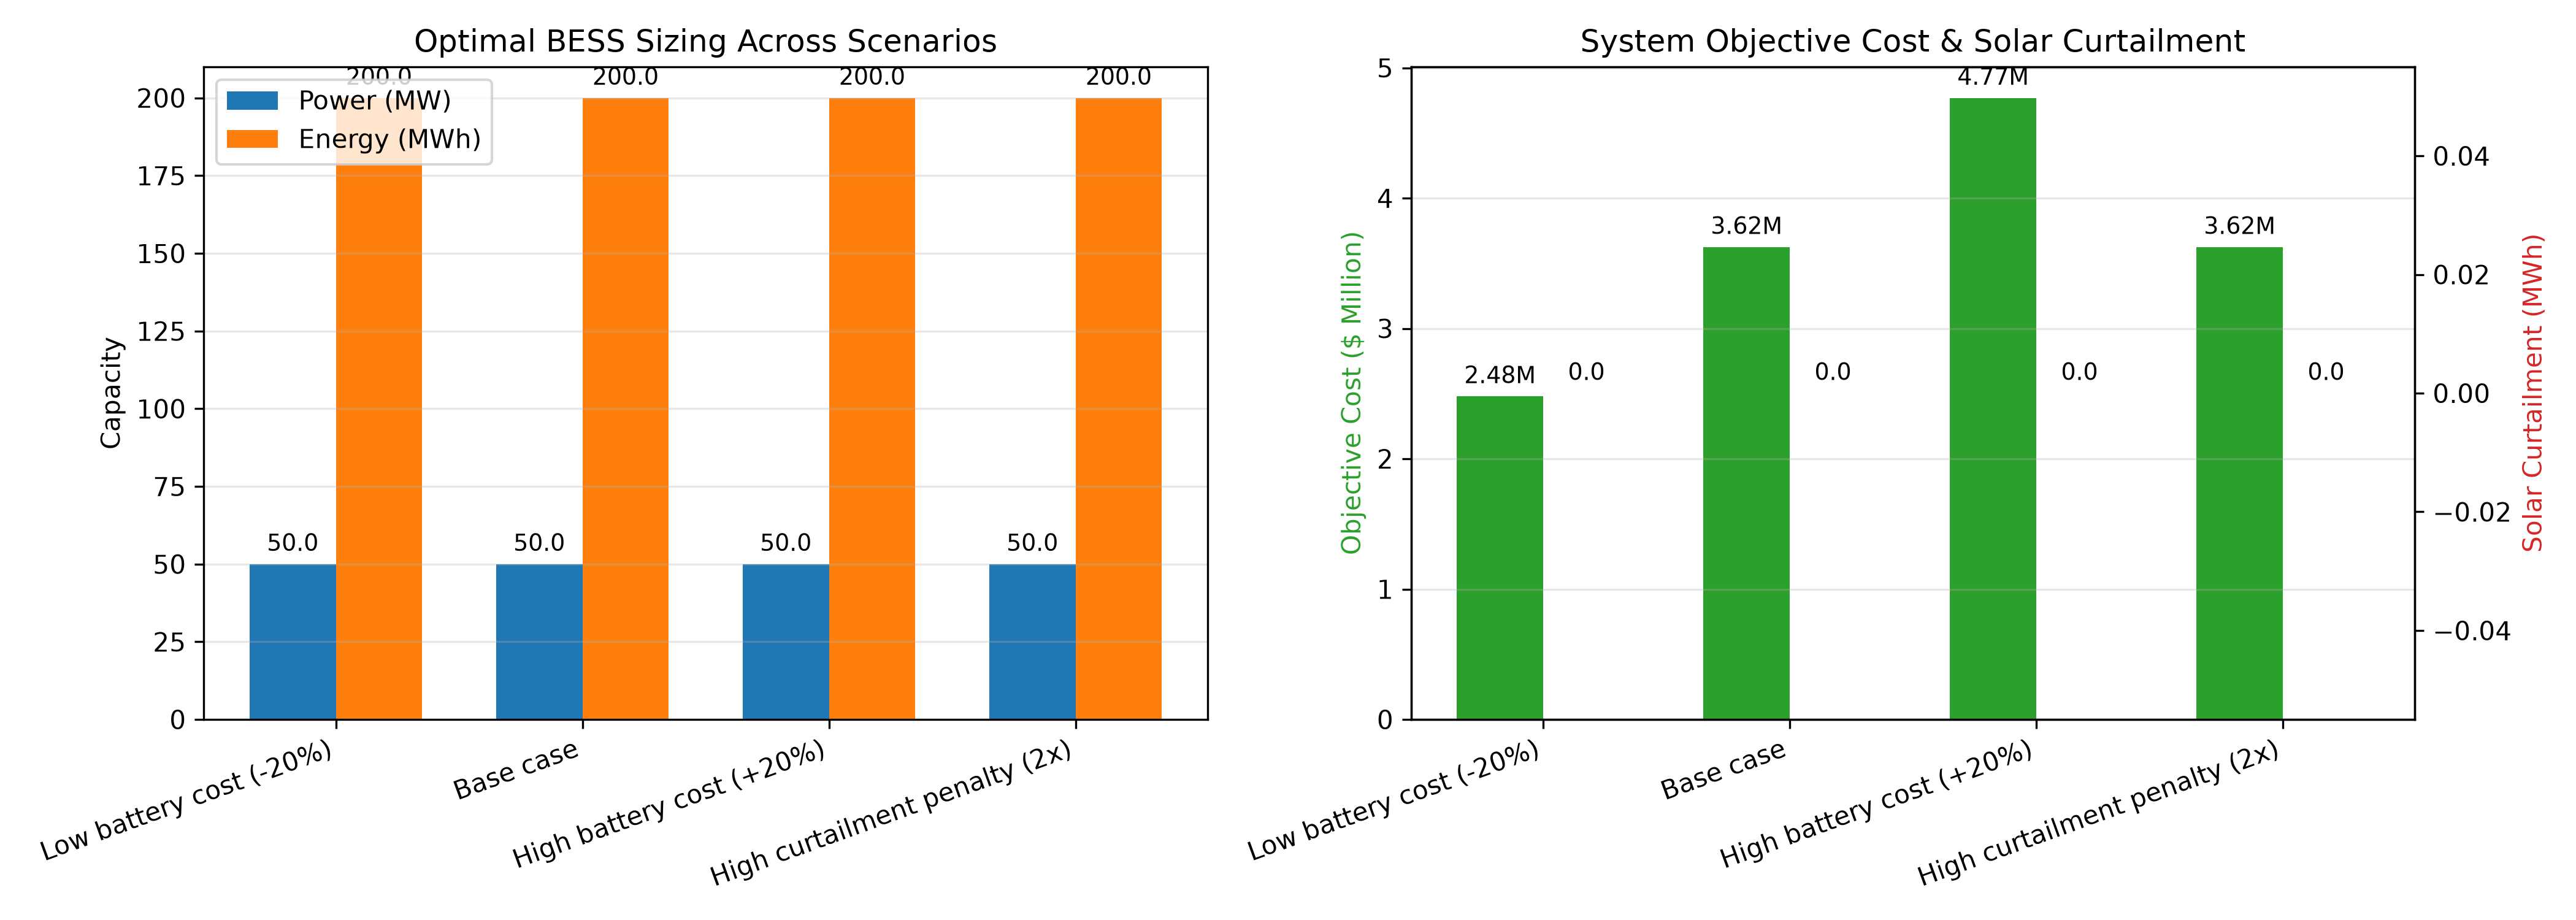

In [9]:
SENSITIVITY.mkdir(parents=True, exist_ok=True)
chart_path = SENSITIVITY / "battery_sensitivity.png"

if not sensitivity_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Panel 1: Sizing (Power & Energy)
    x = range(len(sensitivity_df))
    width = 0.35
    scenarios_labels = sensitivity_df["scenario"]

    bars_power = axes[0].bar([i - width/2 for i in x], sensitivity_df["total_power_mw"], width=width, label="Power (MW)", color="#1f77b4")
    bars_energy = axes[0].bar([i + width/2 for i in x], sensitivity_df["total_energy_mwh"], width=width, label="Energy (MWh)", color="#ff7f0e")

    axes[0].set_title("Optimal BESS Sizing Across Scenarios", fontsize=12)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(scenarios_labels, rotation=20, ha="right")
    axes[0].set_ylabel("Capacity")
    axes[0].grid(axis="y", alpha=0.3)
    axes[0].legend(loc="upper left")

    for container in axes[0].containers:
        axes[0].bar_label(container, fmt="%.1f", padding=3, fontsize=9)

    # Panel 2: Objective Value & Solar Curtailment
    ax2 = axes[1].twinx()
    bars_obj = axes[1].bar([i - width/2 for i in x], sensitivity_df["objective_value_usd"] / 1e6, width=width, label="Total Cost ($M)", color="#2ca02c")
    bars_curt = ax2.bar([i + width/2 for i in x], sensitivity_df["curtailment_mwh"], width=width, label="Curtailment (MWh)", color="#d62728")

    axes[1].set_title("System Objective Cost & Solar Curtailment", fontsize=12)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(scenarios_labels, rotation=20, ha="right")
    axes[1].set_ylabel("Objective Cost ($ Million)", color="#2ca02c")
    ax2.set_ylabel("Solar Curtailment (MWh)", color="#d62728")
    axes[1].grid(axis="y", alpha=0.3)

    for container in axes[1].containers:
        axes[1].bar_label(container, fmt="%.2fM", padding=3, fontsize=9)
    for container in ax2.containers:
        ax2.bar_label(container, fmt="%.1f", padding=3, fontsize=9)

    plt.tight_layout()
    fig.savefig(chart_path, dpi=300)
    plt.show()
    print(f"Sensitivity chart saved to: {chart_path}")
else:
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.axis("off")
    details = [
        "Battery Sensitivity Analysis",
        "Sensitivity chart is unavailable because optimization inputs are not yet populated.",
        f"Expected files: {PROCESSED / 'optimization_profile.csv'} and {PROCESSED / 'candidate_bess_sites.csv'}",
        "Run notebook 06 after preparing grid data to enable this analysis."
    ]
    ax.text(0.5, 0.5, "\n".join(details), ha="center", va="center", fontsize=11, wrap=True)
    fig.tight_layout()
    fig.savefig(chart_path, dpi=300)
    plt.show()
    print(f"Placeholder sensitivity chart saved to: {chart_path}")


### Save results

In [11]:
SENSITIVITY.mkdir(parents=True, exist_ok=True)
output_csv = SENSITIVITY / "sensitivity_results.csv"

sensitivity_df.to_csv(output_csv, index=False)

if sensitivity_df.empty:
    print(f"Initialized sensitivity results template at {output_csv} (0 scenarios executed).")
else:
    print(f"Saved {len(sensitivity_df)} sensitivity scenario results to {output_csv}:")
    display(sensitivity_df)


Saved 4 sensitivity scenario results to D:\My_Project\Analyse\4G-Network-Coverage-Optimization\results\sensitivity\sensitivity_results.csv:


scenario,cost_multiplier,curtailment_penalty_usd_per_mwh,objective_value_usd,number_of_sites,total_power_mw,total_energy_mwh,peak_residual_mw,curtailment_mwh
Low battery cost (-20%),0.8,40,2.479119e+06,1,50.0,200.0,2600.0,0.0
Base case,1.0,40,3.623899e+06,1,50.0,200.0,2600.0,0.0
High battery cost (+20%),1.2,40,4.768679e+06,1,50.0,200.0,2600.0,0.0
High curtailment penalty (2x),1.0,80,3.623899e+06,1,50.0,200.0,2600.0,0.0
